C:\Users\VICTUS\AppData\Local\Temp\ipykernel_24088\1411749847.py:21: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout() # Prevents the legend from being cut off


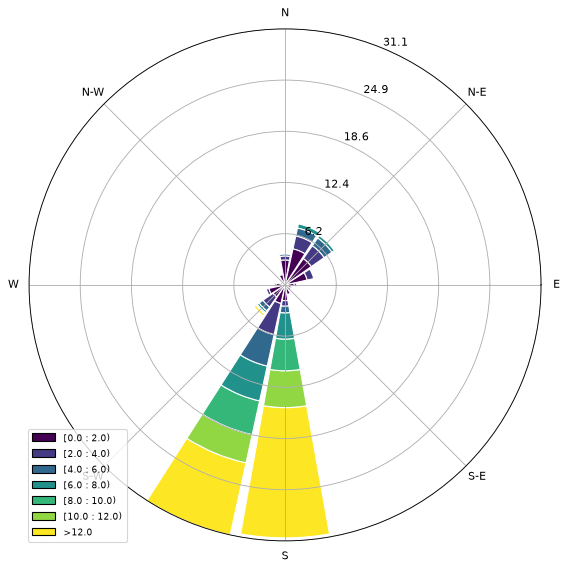

In [1]:
import pandas as pd
from windrose import WindroseAxes
import matplotlib.pyplot as plt

# Use the exact name of the sheet instead of the number 3
df = pd.read_excel(r'D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\Tangbe wind data.xlsx', sheet_name='10Tangbe')

# Drop rows where wind direction or wind speed is missing (NaN)
df_clean = df.dropna(subset=['d78.5_wind_direction_mean', 'a80_wind_speed_mean'])

# Create the Windrose plot
ax = WindroseAxes.from_ax()
ax.bar(df_clean['d78.5_wind_direction_mean'], 
       df_clean['a80_wind_speed_mean'], 
       normed=True, 
       opening=0.9, 
       edgecolor='white', 
       bins=[0, 2, 4, 6, 8, 10, 12])

ax.set_legend()
plt.tight_layout() # Prevents the legend from being cut off
plt.show()

In [21]:
"""
01_load_and_clean.py
Load raw Tangbe met mast data, assess data completeness, save cleaned dataframe.
Site: NEP_Wind_Tangbe_4, Mustang, Nepal. Elevation 3040 m. 80 m guyed lattice mast.
Source: World Bank ESMAP wind measurement campaign.
"""
import pandas as pd
import numpy as np
from pathlib import Path

# ==== EDIT THIS ONE LINE to point at your Lab folder ====
LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

RAW = LAB_DIR / "Tangbe wind data.xlsx"
OUT = DATA_DIR / "clean_data.parquet"

df = pd.read_excel(RAW, sheet_name="10Tangbe")
df["time"] = pd.to_datetime(df["time"])
df = df.set_index("time").sort_index()

heights = [20, 40, 60, 80]
speed_cols = {h: f"a{h}_wind_speed_mean" for h in heights}

# --- Data completeness report ---
print("=== Overall completeness (mean wind speed columns) ===")
for h, c in speed_cols.items():
    valid = df[c].notna().sum()
    total = len(df)
    print(f"  {h:>3} m : {valid:>6}/{total} valid  ({100*valid/total:5.1f}%)  mean={df[c].mean():.2f} m/s")

print("\n=== Monthly completeness at 40 m (most complete sensor) ===")
monthly = df["a40_wind_speed_mean"].notna().groupby(df.index.to_period("M")).mean() * 100
print(monthly.round(1))

print("\n=== Monthly completeness at 80 m ===")
monthly80 = df["a80_wind_speed_mean"].notna().groupby(df.index.to_period("M")).mean() * 100
print(monthly80.round(1))

print(f"\nCampaign span: {df.index.min()} to {df.index.max()}  "
      f"({(df.index.max()-df.index.min()).days} days)")

df.to_parquet(OUT)
print(f"\nSaved cleaned frame to {OUT}, shape={df.shape}")

=== Overall completeness (mean wind speed columns) ===
   20 m :   3375/33984 valid  (  9.9%)  mean=6.47 m/s
   40 m :  33960/33984 valid  ( 99.9%)  mean=7.39 m/s
   60 m :   3372/33984 valid  (  9.9%)  mean=6.87 m/s
   80 m :  19326/33984 valid  ( 56.9%)  mean=7.27 m/s

=== Monthly completeness at 40 m (most complete sensor) ===
time
2019-04     99.9
2019-05     99.9
2019-06    100.0
2019-07     99.9
2019-08    100.0
2019-09     99.9
2019-10     99.9
2019-11    100.0
Freq: M, Name: a40_wind_speed_mean, dtype: float64

=== Monthly completeness at 80 m ===
time
2019-04    100.0
2019-05    100.0
2019-06    100.0
2019-07     84.8
2019-08     41.6
2019-09     17.8
2019-10      2.0
2019-11     20.3
Freq: M, Name: a80_wind_speed_mean, dtype: float64

Campaign span: 2019-04-08 00:00:00 to 2019-11-30 23:50:00  (236 days)

Saved cleaned frame to D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis\data\clean_data.parquet, shape=(33984, 41)


In [22]:
"""
02_shear_and_density.py
- Compute wind shear exponent (power law) from concurrent multi-height data.
- Compute actual air density from station pressure/temperature (elevation 3040 m).
- Extrapolate 40 m wind speed series to hub height using derived shear exponent.
"""
import pandas as pd
import numpy as np
from pathlib import Path

LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_DIR / "clean_data.parquet")

heights = np.array([20, 40, 60, 80])
speed_cols = [f"a{h}_wind_speed_mean" for h in heights]

# --- Wind shear exponent (power law): v2/v1 = (h2/h1)^alpha ---
# Use timestamps where ALL FOUR heights are valid simultaneously (concurrent fit),
# fit ln(v) = ln(v_ref) + alpha * ln(h/h_ref) via least squares per timestamp.
sub = df[speed_cols].dropna()
print(f"Timestamps with all 4 heights valid concurrently: {len(sub)} "
      f"({100*len(sub)/len(df):.1f}% of records)")

log_h = np.log(heights)
alphas = []
for _, row in sub.iterrows():
    v = row.values.astype(float)
    v = np.where(v <= 0, np.nan, v)
    if np.isnan(v).any():
        continue
    log_v = np.log(v)
    # linear regression log_v = a + alpha*log_h
    A = np.vstack([np.ones_like(log_h), log_h]).T
    coef, *_ = np.linalg.lstsq(A, log_v, rcond=None)
    alphas.append(coef[1])

alphas = np.array(alphas)
alpha_mean = np.nanmean(alphas)
alpha_median = np.nanmedian(alphas)
print(f"\nShear exponent alpha: mean={alpha_mean:.4f}, median={alpha_median:.4f}, "
      f"std={np.nanstd(alphas):.4f}  (n={len(alphas)})")

# Sanity check using simple 40m-80m pair over their common valid period
pair = df[["a40_wind_speed_mean", "a80_wind_speed_mean"]].dropna()
alpha_pair = np.log(pair["a80_wind_speed_mean"] / pair["a40_wind_speed_mean"]) / np.log(80/40)
alpha_pair = alpha_pair.replace([np.inf, -np.inf], np.nan).dropna()
print(f"Cross-check (40m-80m pair only): alpha median = {alpha_pair.median():.4f}  (n={len(alpha_pair)})")

ALPHA = round(float(alpha_median), 3)
print(f"\n--> Using alpha = {ALPHA} for extrapolation")

# --- Air density from actual station data (ideal gas law) ---
# rho = p / (R_specific * T), p in Pa, T in Kelvin, R_specific(dry air) = 287.05 J/(kg K)
R = 287.05
p_hpa = df["p5_air_pressure_mean"]          # hPa
t_c = df["t5_temperature_mean"]              # deg C
rho = (p_hpa * 100) / (R * (t_c + 273.15))   # kg/m^3

print(f"\n=== Air density (from station pressure/temp @ 5 m, elevation 3040 m) ===")
print(f"  mean rho = {rho.mean():.4f} kg/m3")
print(f"  min/max  = {rho.min():.4f} / {rho.max():.4f} kg/m3")
print(f"  (sea-level standard = 1.225 kg/m3 -> site density is "
      f"{100*rho.mean()/1.225:.1f}% of sea level)")

RHO_MEAN = float(rho.mean())

# --- Extrapolate 40 m series (most complete) to hub height using ALPHA ---
HUB_HEIGHT = 100  # m -- chosen hub height for candidate turbine (see script 03 for rationale)
v40 = df["a40_wind_speed_mean"]
v_hub = v40 * (HUB_HEIGHT / 40) ** ALPHA

print(f"\n=== Extrapolated hub-height ({HUB_HEIGHT} m) wind speed from 40 m series ===")
print(f"  n valid = {v_hub.notna().sum()}")
print(f"  mean = {v_hub.mean():.3f} m/s, std = {v_hub.std():.3f} m/s")
print(f"  min/max = {v_hub.min():.3f} / {v_hub.max():.3f} m/s")

out = pd.DataFrame({
    "v40": v40,
    "v_hub": v_hub,
    "rho": rho,
})
out.attrs["alpha"] = ALPHA
out.attrs["rho_mean"] = RHO_MEAN
out.attrs["hub_height"] = HUB_HEIGHT
out.to_parquet(DATA_DIR / "hub_series.parquet")

# save scalar summary for later scripts
import json
summary = {"alpha": ALPHA, "rho_mean": RHO_MEAN, "hub_height": HUB_HEIGHT,
           "elevation_m": 3040, "n_hub_valid": int(v_hub.notna().sum())}
with open(DATA_DIR / "site_constants.json", "w") as f:
    json.dump(summary, f, indent=2)
print("\nSaved hub_series.parquet and site_constants.json")

Timestamps with all 4 heights valid concurrently: 3368 (9.9% of records)

Shear exponent alpha: mean=0.0230, median=0.0501, std=0.2240  (n=3368)
Cross-check (40m-80m pair only): alpha median = 0.0300  (n=19310)

--> Using alpha = 0.05 for extrapolation

=== Air density (from station pressure/temp @ 5 m, elevation 3040 m) ===
  mean rho = 0.8529 kg/m3
  min/max  = 0.8174 / 0.8997 kg/m3
  (sea-level standard = 1.225 kg/m3 -> site density is 69.6% of sea level)

=== Extrapolated hub-height (100 m) wind speed from 40 m series ===
  n valid = 33960
  mean = 7.733 m/s, std = 5.495 m/s
  min/max = 0.001 / 23.378 m/s

Saved hub_series.parquet and site_constants.json


In [23]:
"""
03_weibull_fit.py
Fit Weibull distribution to hub-height wind speed (two methods), compute power density.
"""
import pandas as pd
import numpy as np
from scipy import stats
from scipy.special import gamma
from pathlib import Path
import json

LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_parquet(DATA_DIR / "hub_series.parquet")
with open(DATA_DIR / "site_constants.json") as f:
    const = json.load(f)

v = df["v_hub"].dropna()
v = v[v > 0.05]  # drop near-zero calm records that break MLE / log fits trivially
print(f"n = {len(v)} valid hub-height records")
print(f"mean = {v.mean():.3f} m/s, std = {v.std():.3f} m/s")

# --- Method 1: Maximum Likelihood Estimation (scipy, floc=0) ---
k_mle, loc, c_mle = stats.weibull_min.fit(v, floc=0)
print(f"\nMLE fit:              k = {k_mle:.3f}, c = {c_mle:.3f} m/s")

# --- Method 2: Method of Moments ---
# c relates to mean via Gamma function: mean = c * Gamma(1+1/k)
# solve iteratively using mean & std (coefficient of variation)
mean_v, std_v = v.mean(), v.std()
cv = std_v / mean_v

def cv_from_k(k):
    return np.sqrt(gamma(1 + 2/k) / gamma(1 + 1/k)**2 - 1)

from scipy.optimize import brentq
k_mom = brentq(lambda k: cv_from_k(k) - cv, 0.5, 10)
c_mom = mean_v / gamma(1 + 1/k_mom)
print(f"Method of moments:    k = {k_mom:.3f}, c = {c_mom:.3f} m/s")

# use MLE as primary
K, C = round(float(k_mle), 3), round(float(c_mle), 3)

# --- Power density (using ACTUAL Weibull-based mean of v^3, not mean^3) ---
rho = const["rho_mean"]
# analytic: E[v^3] for Weibull = c^3 * Gamma(1 + 3/k)
Ev3_weibull = C**3 * gamma(1 + 3/K)
Ev3_empirical = (v**3).mean()
power_density_weibull = 0.5 * rho * Ev3_weibull
power_density_empirical = 0.5 * rho * Ev3_empirical

print(f"\nE[v^3] Weibull-analytic = {Ev3_weibull:.2f}  |  empirical = {Ev3_empirical:.2f}")
print(f"Power density (Weibull) = {power_density_weibull:.2f} W/m2")
print(f"Power density (empirical) = {power_density_empirical:.2f} W/m2")

# Wind class reference (rough IEC/typical siting guide, informational only)
print(f"\nFor reference: >400 W/m2 is generally considered a good utility-scale site.")

const.update({
    "weibull_k": K, "weibull_c": C,
    "k_mom": round(float(k_mom),3), "c_mom": round(float(c_mom),3),
    "mean_v_hub": round(float(mean_v),3),
    "power_density_Wm2": round(float(power_density_weibull),2),
})
with open(DATA_DIR / "site_constants.json", "w") as f:
    json.dump(const, f, indent=2)

v.to_frame("v_hub").to_parquet(DATA_DIR / "v_hub_clean.parquet")
print("\nUpdated site_constants.json")

n = 33921 valid hub-height records
mean = 7.741 m/s, std = 5.492 m/s

MLE fit:              k = 1.297, c = 8.340 m/s
Method of moments:    k = 1.431, c = 8.521 m/s

E[v^3] Weibull-analytic = 1577.82  |  empirical = 1219.81
Power density (Weibull) = 672.86 W/m2
Power density (empirical) = 520.19 W/m2

For reference: >400 W/m2 is generally considered a good utility-scale site.

Updated site_constants.json


In [24]:
"""
04_turbine_design.py
Size a rotor for a chosen rated power using ACTUAL site air density (not sea-level standard).
Generate Cp-lambda curve (Heier/Slootweg empirical model) and the turbine power curve.
"""
import numpy as np
import json
from pathlib import Path
from scipy.optimize import minimize_scalar

LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA_DIR / "site_constants.json") as f:
    C = json.load(f)

RHO = C["rho_mean"]          # actual site air density, kg/m3
RATED_POWER = 2_000_000.0    # W -- design choice: 2 MW class turbine
V_RATED = 11.0                # m/s -- design choice
V_CUTIN = 3.0
V_CUTOUT = 25.0
CP_DESIGN = 0.45              # realistic achievable Cp (Betz limit = 0.593)
GEARBOX_DRIVETRAIN_EFF = 0.94 # mechanical-to-electrical conversion losses (gearbox/generator/converter)

# --- Cp(lambda, beta) empirical model (Heier / Slootweg formulation) ---
def cp(lam, beta=0.0):
    if lam <= 0:
        return 0.0
    inv_li = 1.0/(lam + 0.08*beta) - 0.035/(beta**3 + 1)
    li = 1.0/inv_li if inv_li != 0 else 1e9
    return 0.5176*(116/li - 0.4*beta - 5)*np.exp(-21/li) + 0.0068*lam

# find optimal TSR (lambda) at beta=0 that maximizes Cp
res = minimize_scalar(lambda l: -cp(l, 0.0), bounds=(1, 20), method="bounded")
lambda_opt = res.x
cp_max = cp(lambda_opt, 0.0)
print(f"Cp-lambda model (pitch=0): lambda_opt = {lambda_opt:.2f}, Cp_max = {cp_max:.4f}")
print(f"(Design Cp used for sizing = {CP_DESIGN}, i.e. {100*CP_DESIGN/cp_max:.0f}% of model peak, "
      f"conservative allowance for real blade/drivetrain losses)")

# --- Rotor sizing from rated aerodynamic power at rated wind speed, using ACTUAL rho ---
# P_rated_electrical = 0.5 * rho * A * Cp * v_rated^3 * eta_drivetrain
A_swept = RATED_POWER / (0.5 * RHO * CP_DESIGN * V_RATED**3 * GEARBOX_DRIVETRAIN_EFF)
D_rotor = np.sqrt(4*A_swept/np.pi)
R_rotor = D_rotor/2

print(f"\n=== Rotor sizing (site air density rho = {RHO:.4f} kg/m3) ===")
print(f"  Swept area required = {A_swept:,.0f} m2")
print(f"  Rotor diameter      = {D_rotor:.1f} m  (radius {R_rotor:.1f} m)")

# comparison: what diameter would be needed at sea-level standard density for same rated power
A_sea = RATED_POWER / (0.5 * 1.225 * CP_DESIGN * V_RATED**3 * GEARBOX_DRIVETRAIN_EFF)
D_sea = np.sqrt(4*A_sea/np.pi)
print(f"  (For comparison, a sea-level site (rho=1.225) would need only D = {D_sea:.1f} m "
      f"for the same {RATED_POWER/1e6:.0f} MW rating)")
print(f"  --> High-altitude site needs {100*(D_rotor/D_sea-1):.1f}% larger rotor diameter "
      f"to compensate for thin air.")

HUB_HEIGHT = C["hub_height"]
tip_clearance = HUB_HEIGHT - R_rotor
print(f"\n  Hub height = {HUB_HEIGHT} m, lowest blade tip clearance above ground = {tip_clearance:.1f} m "
      f"({'OK' if tip_clearance > 15 else 'TOO LOW - increase hub height or reduce rotor'})")

rated_rpm_tsr = lambda_opt * V_RATED / R_rotor * 60 / (2*np.pi)
print(f"  Approx rotor speed at rated wind speed (optimal TSR tracking) = {rated_rpm_tsr:.1f} rpm")

# --- Generate full power curve P(v) ---
v_range = np.arange(0, 30.01, 0.1)
P = np.zeros_like(v_range)

for i, v in enumerate(v_range):
    if v < V_CUTIN or v > V_CUTOUT:
        P[i] = 0.0
    elif v < V_RATED:
        # MPPT region: Cp held near Cp_design (variable speed tracks optimal TSR)
        p = 0.5 * RHO * A_swept * CP_DESIGN * v**3 * GEARBOX_DRIVETRAIN_EFF
        P[i] = min(p, RATED_POWER)
    else:
        # rated region: pitch control holds output at rated power
        P[i] = RATED_POWER

np.save(DATA_DIR / "power_curve_v.npy", v_range)
np.save(DATA_DIR / "power_curve_P.npy", P)

C.update({
    "rated_power_W": RATED_POWER, "v_rated": V_RATED, "v_cutin": V_CUTIN, "v_cutout": V_CUTOUT,
    "cp_design": CP_DESIGN, "cp_max_model": round(float(cp_max),4),
    "lambda_opt": round(float(lambda_opt),3),
    "rotor_diameter_m": round(float(D_rotor),2), "rotor_area_m2": round(float(A_swept),1),
    "drivetrain_eff": GEARBOX_DRIVETRAIN_EFF,
    "tip_clearance_m": round(float(tip_clearance),1),
})
with open(DATA_DIR / "site_constants.json", "w") as f:
    json.dump(C, f, indent=2)

print("\nSaved power curve arrays and updated site_constants.json")

Cp-lambda model (pitch=0): lambda_opt = 8.10, Cp_max = 0.4800
(Design Cp used for sizing = 0.45, i.e. 94% of model peak, conservative allowance for real blade/drivetrain losses)

=== Rotor sizing (site air density rho = 0.8529 kg/m3) ===
  Swept area required = 8,330 m2
  Rotor diameter      = 103.0 m  (radius 51.5 m)
  (For comparison, a sea-level site (rho=1.225) would need only D = 85.9 m for the same 2 MW rating)
  --> High-altitude site needs 19.8% larger rotor diameter to compensate for thin air.

  Hub height = 100 m, lowest blade tip clearance above ground = 48.5 m (OK)
  Approx rotor speed at rated wind speed (optimal TSR tracking) = 16.5 rpm

Saved power curve arrays and updated site_constants.json


In [25]:
"""
05_aep_capacity_factor.py
Compute AEP two ways:
 (a) Analytic: integrate power curve against fitted Weibull PDF
 (b) Empirical: apply power curve directly to the observed hub-height time series
Compare the two and compute capacity factor.
"""
import numpy as np
import pandas as pd
import json
from pathlib import Path
from scipy import stats

LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA_DIR / "site_constants.json") as f:
    C = json.load(f)

v_range = np.load(DATA_DIR / "power_curve_v.npy")
P = np.load(DATA_DIR / "power_curve_P.npy")

K, SCALE = C["weibull_k"], C["weibull_c"]
RATED_POWER = C["rated_power_W"]

# --- (a) Analytic: AEP = 8760 * integral[ P(v) * f_weibull(v) dv ] ---
f_weibull = stats.weibull_min.pdf(v_range, K, loc=0, scale=SCALE)
mean_power_weibull = np.trapezoid(P * f_weibull, v_range)  # W
AEP_weibull = mean_power_weibull * 8760 / 1e6  # MWh

print(f"=== Method (a): Weibull-analytic ===")
print(f"  Mean electrical power = {mean_power_weibull/1000:.1f} kW")
print(f"  AEP = {AEP_weibull:,.1f} MWh/year")
print(f"  Capacity factor = {100*mean_power_weibull/RATED_POWER:.1f}%")

# --- (b) Empirical: apply power curve to actual observed hub-height series ---
v_hub = pd.read_parquet(DATA_DIR / "v_hub_clean.parquet")["v_hub"]
P_interp = np.interp(v_hub.values, v_range, P, left=0, right=0)
mean_power_emp = P_interp.mean()
AEP_emp = mean_power_emp * 8760 / 1e6

print(f"\n=== Method (b): Empirical (measured time series through power curve) ===")
print(f"  n observations used = {len(v_hub)}")
print(f"  Mean electrical power = {mean_power_emp/1000:.1f} kW")
print(f"  AEP = {AEP_emp:,.1f} MWh/year")
print(f"  Capacity factor = {100*mean_power_emp/RATED_POWER:.1f}%")

print(f"\nNote: empirical estimate is drawn from an 8-month campaign (Apr-Nov 2019); "
      f"it does not capture a full annual cycle (missing Dec-Mar, which in many Himalayan "
      f"sites includes strong pre-monsoon spring winds already partly captured, but winter "
      f"conditions are absent). Treat as indicative, not a bankable P50 estimate -- a bankable "
      f"figure would need long-term correlation (MCP) against a nearby reference station.")

# time-of-day / seasonal breakdown (descriptive, using available months only)
v_hub_df = v_hub.to_frame("v_hub")
v_hub_df["month"] = v_hub_df.index.month
monthly_mean_v = v_hub_df.groupby("month")["v_hub"].mean()
print(f"\nMonthly mean hub-height wind speed (m/s), available months only:")
print(monthly_mean_v.round(2))

C.update({
    "AEP_weibull_MWh": round(float(AEP_weibull), 1),
    "AEP_empirical_MWh": round(float(AEP_emp), 1),
    "capacity_factor_weibull_pct": round(100*float(mean_power_weibull/RATED_POWER), 2),
    "capacity_factor_empirical_pct": round(100*float(mean_power_emp/RATED_POWER), 2),
})
with open(DATA_DIR / "site_constants.json", "w") as f:
    json.dump(C, f, indent=2)
print("\nUpdated site_constants.json")

=== Method (a): Weibull-analytic ===
  Mean electrical power = 742.8 kW
  AEP = 6,506.8 MWh/year
  Capacity factor = 37.1%

=== Method (b): Empirical (measured time series through power curve) ===
  n observations used = 33921
  Mean electrical power = 895.3 kW
  AEP = 7,843.0 MWh/year
  Capacity factor = 44.8%

Note: empirical estimate is drawn from an 8-month campaign (Apr-Nov 2019); it does not capture a full annual cycle (missing Dec-Mar, which in many Himalayan sites includes strong pre-monsoon spring winds already partly captured, but winter conditions are absent). Treat as indicative, not a bankable P50 estimate -- a bankable figure would need long-term correlation (MCP) against a nearby reference station.

Monthly mean hub-height wind speed (m/s), available months only:
month
4     7.13
5     8.23
6     9.23
7     8.76
8     7.78
9     8.24
10    6.76
11    5.61
Name: v_hub, dtype: float64

Updated site_constants.json


In [26]:
import pandas as pd
import numpy as np
import json
from pathlib import Path
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
from scipy import stats

plt.rcParams.update({"font.size": 11, "font.family": "DejaVu Sans"})

LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
FIGDIR = LAB_DIR / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)

df_raw = pd.read_parquet(DATA_DIR / "clean_data.parquet")
hub = pd.read_parquet(DATA_DIR / "hub_series.parquet")
v_hub = pd.read_parquet(DATA_DIR / "v_hub_clean.parquet")["v_hub"]
with open(DATA_DIR / "site_constants.json") as f:
    C = json.load(f)
v_range = np.load(DATA_DIR / "power_curve_v.npy")
P = np.load(DATA_DIR / "power_curve_P.npy")

# --- Fig 1: Data completeness by month/height ---
heights = [20, 40, 60, 80]
fig, ax = plt.subplots(figsize=(8, 4.5))
for h in heights:
    col = f"a{h}_wind_speed_mean"
    monthly = df_raw[col].notna().groupby(df_raw.index.to_period("M")).mean() * 100
    ax.plot(monthly.index.astype(str), monthly.values, marker="o", label=f"{h} m")
ax.set_ylabel("Data completeness (%)")
ax.set_xlabel("Month")
ax.set_title("Sensor data completeness by height, Tangbe met mast 2019")
ax.legend()
ax.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/01_data_completeness.png", dpi=150)
plt.close()

# --- Fig 2: Weibull fit vs histogram at hub height ---
K, SCALE = C["weibull_k"], C["weibull_c"]
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.hist(v_hub, bins=60, density=True, alpha=0.55, color="#4C72B0", label="Observed (10-min means)")
vv = np.linspace(0.01, 30, 300)
ax.plot(vv, stats.weibull_min.pdf(vv, K, loc=0, scale=SCALE), "r-", lw=2.2,
        label=f"Weibull fit (k={K:.2f}, c={SCALE:.2f} m/s)")
ax.set_xlabel("Wind speed at hub height (m/s)")
ax.set_ylabel("Probability density")
ax.set_title(f"Wind speed distribution at {C['hub_height']} m hub height (extrapolated)")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/02_weibull_fit.png", dpi=150)
plt.close()

# --- Fig 3: Wind shear profile (log height vs mean speed at each level) ---
means = {h: df_raw[f"a{h}_wind_speed_mean"].mean() for h in heights}
fig, ax = plt.subplots(figsize=(6.5, 5))
hs = np.array(list(means.keys()))
vs = np.array(list(means.values()))
ax.scatter(hs, vs, color="#C44E52", zorder=3, s=60, label="Measured mean speed")
h_fit = np.linspace(15, 110, 100)
v_fit = vs[hs == 40][0] * (h_fit/40) ** C["alpha"]
ax.plot(h_fit, v_fit, "--", color="#4C72B0", label=f"Power law fit ($\\alpha$={C['alpha']})")
ax.axvline(C["hub_height"], color="gray", ls=":", label=f"Hub height ({C['hub_height']} m)")
ax.set_xlabel("Height above ground (m)")
ax.set_ylabel("Mean wind speed (m/s)")
ax.set_title("Vertical wind shear profile, Tangbe site")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/03_shear_profile.png", dpi=150)
plt.close()

# --- Fig 4: Cp-lambda curve ---
def cp(lam, beta=0.0):
    lam = np.asarray(lam, dtype=float)
    inv_li = 1.0/(lam + 0.08*beta) - 0.035/(beta**3 + 1)
    li = 1.0/inv_li
    return 0.5176*(116/li - 0.4*beta - 5)*np.exp(-21/li) + 0.0068*lam

lam_range = np.linspace(0.5, 16, 300)
fig, ax = plt.subplots(figsize=(6.5, 5))
for beta in [0, 5, 10, 15]:
    ax.plot(lam_range, cp(lam_range, beta), label=f"pitch $\\beta$={beta}°")
ax.axhline(0.593, color="k", ls="--", lw=1, label="Betz limit (0.593)")
ax.axvline(C["lambda_opt"], color="gray", ls=":", lw=1)
ax.set_xlabel("Tip speed ratio, $\\lambda$")
ax.set_ylabel("Power coefficient, $C_p$")
ax.set_title("$C_p$-$\\lambda$ curve (Heier/Slootweg empirical model)")
ax.legend(fontsize=9)
ax.grid(alpha=0.3)
ax.set_ylim(0, 0.65)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/04_cp_lambda.png", dpi=150)
plt.close()

# --- Fig 5: Power curve ---
fig, ax = plt.subplots(figsize=(7.5, 5))
ax.plot(v_range, P/1e6, lw=2.2, color="#55A868")
ax.axvline(C["v_cutin"], color="gray", ls=":", lw=1)
ax.axvline(C["v_rated"], color="gray", ls=":", lw=1)
ax.axvline(C["v_cutout"], color="gray", ls=":", lw=1)
ax.text(C["v_cutin"], -0.15, "cut-in", ha="center", fontsize=8)
ax.text(C["v_rated"], -0.15, "rated", ha="center", fontsize=8)
ax.text(C["v_cutout"], -0.15, "cut-out", ha="center", fontsize=8)
ax.set_xlabel("Wind speed (m/s)")
ax.set_ylabel("Electrical power output (MW)")
ax.set_title(f"Turbine power curve  (D={C['rotor_diameter_m']} m, rated={C['rated_power_W']/1e6:.0f} MW, "
             f"$\\rho$={C['rho_mean']:.3f} kg/m$^3$)")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{FIGDIR}/05_power_curve.png", dpi=150)
plt.close()

# --- Fig 6: Monthly mean wind speed at hub height (available months) ---
hub_df = v_hub.to_frame("v_hub")
hub_df["month"] = hub_df.index.month_name().str[:3]
order = ["Apr","May","Jun","Jul","Aug","Sep","Oct","Nov"]
monthly_v = hub_df.groupby("month")["v_hub"].mean().reindex(order)
fig, ax = plt.subplots(figsize=(7, 4.5))
ax.bar(monthly_v.index, monthly_v.values, color="#8172B2")
ax.set_ylabel("Mean wind speed at hub height (m/s)")
ax.set_title("Monthly mean wind speed (Apr-Nov 2019 campaign, no full annual cycle)")
ax.grid(alpha=0.3, axis="y")
plt.tight_layout()
plt.savefig(f"{FIGDIR}/06_monthly_wind.png", dpi=150)
plt.close()

print("All 6 figures saved to", FIGDIR)
import os
print(os.listdir(FIGDIR))

All 6 figures saved to D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis\figures
['01_data_completeness.png', '02_weibull_fit.png', '03_shear_profile.png', '04_cp_lambda.png', '05_power_curve.png', '06_monthly_wind.png']


In [27]:
"""
07_economics.py
Simple LCOE calculation. CAPEX/OPEX are stated assumptions (typical utility-scale wind
figures adjusted for a mountainous, road-access-constrained Nepal site) -- NOT derived
from the wind data itself. Clearly labeled as assumptions for the report.
"""
import json
import numpy as np
from pathlib import Path

LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis")
DATA_DIR = LAB_DIR / "data"
DATA_DIR.mkdir(parents=True, exist_ok=True)

with open(DATA_DIR / "site_constants.json") as f:
    C = json.load(f)

RATED_MW = C["rated_power_W"] / 1e6
AEP_MWh = C["AEP_empirical_MWh"]   # use empirical (measured) AEP as base case

# --- Assumptions (clearly flagged; adjust to match your professor's / country figures) ---
CAPEX_PER_KW = 1500       # USD/kW -- global utility-scale wind typically 1200-1700 USD/kW;
                          # Nepal mountainous/remote sites trend to the higher end due to
                          # transport & access-road costs (no road-specific premium added here)
OPEX_PER_KW_YR = 40       # USD/kW/year -- typical 2-3% of CAPEX/year
DISCOUNT_RATE = 0.08      # WACC, typical for Nepal infrastructure project
LIFETIME_YEARS = 20
DEGRADATION = 0.005       # 0.5%/year output degradation

capex_total = CAPEX_PER_KW * RATED_MW * 1000
opex_annual = OPEX_PER_KW_YR * RATED_MW * 1000

years = np.arange(1, LIFETIME_YEARS + 1)
energy_stream = AEP_MWh * (1 - DEGRADATION) ** (years - 1)
discount_factor = 1 / (1 + DISCOUNT_RATE) ** years

npv_costs = capex_total + np.sum(opex_annual * discount_factor)
npv_energy = np.sum(energy_stream * discount_factor)

LCOE = npv_costs / npv_energy  # USD/MWh
LCOE_per_kWh = LCOE / 1000

print("=== Economic assumptions ===")
print(f"  CAPEX = {CAPEX_PER_KW} USD/kW  -> total CAPEX = ${capex_total:,.0f}")
print(f"  OPEX  = {OPEX_PER_KW_YR} USD/kW/yr -> annual OPEX = ${opex_annual:,.0f}")
print(f"  Discount rate = {DISCOUNT_RATE*100:.0f}%,  Lifetime = {LIFETIME_YEARS} yr,  "
      f"Degradation = {DEGRADATION*100:.1f}%/yr")

print(f"\n=== LCOE result ===")
print(f"  AEP (base case, empirical) = {AEP_MWh:,.0f} MWh/yr")
print(f"  LCOE = ${LCOE:.1f}/MWh = ${LCOE_per_kWh:.3f}/kWh (NPR ~{LCOE_per_kWh*133:.1f}/kWh @ ~133 NPR/USD)")

# Sensitivity: also compute using Weibull-analytic AEP (lower estimate)
AEP_low = C["AEP_weibull_MWh"]
energy_stream_low = AEP_low * (1 - DEGRADATION) ** (years - 1)
npv_energy_low = np.sum(energy_stream_low * discount_factor)
LCOE_low_case = npv_costs / npv_energy_low
print(f"\n  Sensitivity: using Weibull-analytic AEP ({AEP_low:,.0f} MWh/yr) instead: "
      f"LCOE = ${LCOE_low_case:.1f}/MWh (${LCOE_low_case/1000:.3f}/kWh)")

print(f"\n  Nepal wind FiT context: Nepal has essentially no utility-scale wind installed "
      f"(~1 MW nationally) and no dedicated, actively-used wind FiT schedule. The closest "
      f"benchmark is utility-scale solar PPAs, which have cleared around NPR 7.3-7.5/kWh "
      f"(e.g. the Mithila 10 MW solar plant at NPR 7.30/kWh). Nepal's FY 2082/83 (2025/26) "
      f"budget signaled intent to price wind/solar feed-in at rates comparable to "
      f"reservoir-hydropower PPAs going forward. Use this only as an order-of-magnitude "
      f"cross-check -- verify the current gazetted rate with AEPC/DoED before submission.")

C.update({
    "capex_per_kW": CAPEX_PER_KW, "opex_per_kW_yr": OPEX_PER_KW_YR,
    "discount_rate": DISCOUNT_RATE, "lifetime_yr": LIFETIME_YEARS,
    "capex_total_usd": round(float(capex_total),0),
    "LCOE_usd_per_MWh": round(float(LCOE),2),
    "LCOE_usd_per_kWh": round(float(LCOE_per_kWh),4),
})
with open(DATA_DIR / "site_constants.json", "w") as f:
    json.dump(C, f, indent=2)
print("\nUpdated site_constants.json")

=== Economic assumptions ===
  CAPEX = 1500 USD/kW  -> total CAPEX = $3,000,000
  OPEX  = 40 USD/kW/yr -> annual OPEX = $80,000
  Discount rate = 8%,  Lifetime = 20 yr,  Degradation = 0.5%/yr

=== LCOE result ===
  AEP (base case, empirical) = 7,843 MWh/yr
  LCOE = $50.9/MWh = $0.051/kWh (NPR ~6.8/kWh @ ~133 NPR/USD)

  Sensitivity: using Weibull-analytic AEP (6,507 MWh/yr) instead: LCOE = $61.4/MWh ($0.061/kWh)

  Nepal wind FiT context: Nepal has essentially no utility-scale wind installed (~1 MW nationally) and no dedicated, actively-used wind FiT schedule. The closest benchmark is utility-scale solar PPAs, which have cleared around NPR 7.3-7.5/kWh (e.g. the Mithila 10 MW solar plant at NPR 7.30/kWh). Nepal's FY 2082/83 (2025/26) budget signaled intent to price wind/solar feed-in at rates comparable to reservoir-hydropower PPAs going forward. Use this only as an order-of-magnitude cross-check -- verify the current gazetted rate with AEPC/DoED before submission.

Updated site_constan

In [19]:
# # WECS Design Model — Tangbe, Nepal

# ## Setup (one-time)
# Open each script and check the `LAB_DIR` line near the top — it's already set to:

#     LAB_DIR = Path(r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab")

# If that's not your actual folder, update it (same line, same format, in all 7 scripts).

# Put your source file at: `LAB_DIR / "Tangbe wind data.xlsx"`
# i.e. `D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\Tangbe wind data.xlsx`

# Everything else (data/ and figures/ subfolders, all intermediate parquet/json/npy files)
# is created automatically inside LAB_DIR — no other paths need editing.

# ## Run in order
# 1. `01_load_and_clean.py`      — loads raw Excel data, reports sensor completeness
# 2. `02_shear_and_density.py`   — wind shear exponent, air density, hub-height extrapolation
# 3. `03_weibull_fit.py`         — Weibull distribution fit (MLE + method of moments), power density
# 4. `04_turbine_design.py`      — Betz-limit rotor sizing, Cp-lambda curve, power curve
# 5. `05_aep_capacity_factor.py` — Annual Energy Production (analytic + empirical), capacity factor
# 6. `06_figures.py`             — generates all 6 report figures into LAB_DIR/figures
# 7. `07_economics.py`           — LCOE calculation

# Requires: pandas, numpy, scipy, matplotlib, openpyxl, pyarrow
# Install: `pip install pandas numpy scipy matplotlib openpyxl pyarrow`

# Each script reads the previous script's saved output from `LAB_DIR/data/`, so run them
# strictly in order the first time. After that you can re-run any single script (e.g. after
# tweaking rated power in `04_turbine_design.py`) as long as its upstream dependencies already ran once.

In [4]:
import pandas as pd
import os

def calculate_daily_monthly_averages():
    # 1. Set up paths
    folder_path = r"D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis"
    file_name = "Tangbe wind data.xlsx" # Change to "Tangbe wind data.xlsx" if %20 is actually a space
    file_path = os.path.join(folder_path, file_name)

    try:
        # 2. READ the "useable data" sheet
        print("Reading data...")
        df = pd.read_excel(file_path, sheet_name='Useable data')

        # 3. CONVERT 'time' column to actual datetime objects
        df['time'] = pd.to_datetime(df['time'])

        # --- CHOOSE YOUR WIND SPEED COLUMN HERE ---
        # Change 'a80_wind_speed_mean' to a40, a60, etc., if you need a different height
        wind_col = 'a80_wind_speed_mean' 

        # 4. EXTRACT Date, Day Name, and Month into new columns
        df['Date'] = df['time'].dt.date
        df['Day'] = df['time'].dt.day_name() 
        df['Month'] = df['time'].dt.to_period('M') 

        # 5. CALCULATE DAILY AVERAGE
        daily_avg = df.groupby('Date')[wind_col].mean().reset_index()
        daily_avg.columns = ['Date', 'Daily average wind speed']

        # 6. GET THE DAY AND MONTH FOR EACH DATE
        # (Because groupby drops the other columns, we need to bring them back)
        date_info = df[['Date', 'Day', 'Month']].drop_duplicates()
        daily_avg = pd.merge(daily_avg, date_info, on='Date')

        # 7. CALCULATE MONTHLY AVERAGE
        monthly_avg = df.groupby('Month')[wind_col].mean().reset_index()
        monthly_avg.columns = ['Month', 'Monthly average wind speed']

        # 8. MERGE daily and monthly averages together
        # Now 'Month' exists in both, so this will work perfectly!
        final_table = pd.merge(daily_avg, monthly_avg, on='Month')

        # 9. FORMAT THE TABLE to match your screenshot exactly
        final_table['HEAD'] = ''
        final_table = final_table[['Date', 'Day', 'Daily average wind speed', 'Month', 'Monthly average wind speed', 'HEAD']]

        # Convert Date and Month to clean string formats
        final_table['Date'] = pd.to_datetime(final_table['Date']).dt.strftime('%Y-%m-%d')
        final_table['Month'] = final_table['Month'].astype(str)

        # 10. WRITE TO A NEW EXCEL FILE
        output_path = os.path.join(folder_path, "Calculated_Average_Table.xlsx")
        print(f"Saving calculated table to: {output_path}")
        final_table.to_excel(output_path, index=False, sheet_name='Daily & Monthly Averages')

        print("\nSuccess! Calculated Daily and Monthly averages.")
        print("You can now open 'Calculated_Average_Table.xlsx' to see the results.")

    except Exception as e:
        print(f"\nAn error occurred: {e}")

if __name__ == "__main__":
    calculate_daily_monthly_averages()

Reading data...
Saving calculated table to: D:\Aaryan\College\College Subjects\Wind Energy Conversion System\Lab\python analysis\Calculated_Average_Table.xlsx

Success! Calculated Daily and Monthly averages.
You can now open 'Calculated_Average_Table.xlsx' to see the results.
